# Лабораторная работа № 3
## Виртуальный анализ 3D-модели робототехнического узла и подготовка к аддитивному производству

**Студент:** Юшкова Ольга Марьяновна  
**Группа:** ИНДОР-221  
**Вариант:** 17

**Деталь:** `rotation_pitch_so101_v1` — узел поворота манипулятора SO-101.  
**Исходный режим:** ABS; слой 0,16 мм; заполнение 30 %; сопло 0,4 мм.  
**Исследовательский фокус:** ориентация и площадь контакта при печати ABS. Масштаб 1,04 исследуется отдельно; печать рекомендуется в масштабе 1:1.

**Цель:** проверить STL-модель, сравнить шесть ориентаций и обосновать режим FDM/FFF-печати расчётами без физического принтера.

Работа выполнена на основе `lab_03_student.ipynb` и методических указаний `lab_03.md`.
Все расчётные ячейки и самопроверки выполняются сверху вниз.
В Colab: **Среда выполнения → Перезапустить сеанс и выполнить все**.
Первый запуск требует интернета для установки библиотек и загрузки STL.
В конце автоматически сохраняются карта печати CSV, `README.md` и рисунки.
Сама тетрадка скачивается через **Файл → Скачать → Скачать IPYNB**, с результатами выполнения.

## 1. Теоретический блок

### 1.1. Где эта работа в цифровом маршруте детали

```
CAD-модель → STL/3MF → ПРОВЕРКА СЕТКИ → ОРИЕНТАЦИЯ → ПАРАМЕТРЫ ПЕЧАТИ → слайсер → G-code → печать → постобработка → контроль
                       └──────────── эта лабораторная работа (виртуально) ────────────┘
```

Ошибка, допущенная на ранних шагах, переносится дальше: незамкнутую сетку слайсер «залатает» по-своему, неверная ориентация даст лишние поддержки и слабую деталь, а масштаб «на глаз» сломает посадку сервопривода. Поэтому инженер сначала **анализирует модель**, и только потом нажимает Print.

### 1.2. Формат STL: что в нём есть и чего нет

STL описывает поверхность тела набором треугольников. Для каждого треугольника хранятся три вершины и нормаль.

| Что есть в STL | Чего в STL **нет** |
|---|---|
| координаты вершин треугольников | единиц измерения |
| нормали граней | цвета, материала, допусков |
| (в ASCII) имя тела | параметрической истории модели |

* **ASCII-STL** — текст (`solid … facet normal … vertex …`), удобен для чтения, но объёмен.
* **Binary-STL** — 80 байт заголовка + 4 байта числа граней + 50 байт на грань: $S = 84 + 50\,F$ байт.
* **Единицы.** Для печати принято считать числа миллиметрами. В робототехнике (URDF, ROS, REP 103) модели часто хранят **в метрах** — деталь 50 мм превратится в слайсере в «пылинку» 0,05 мм. Единицы нужно **проверять по габаритам**.
* **3MF** хранит единицы, несколько тел, цвета и параметры печати. Для сложных проектов он предпочтительнее STL.

### 1.3. Качество сетки: почему `is_watertight` важнее, чем кажется

* **Замкнутость (watertight, manifold).** Каждое ребро принадлежит ровно двум треугольникам, поверхность не имеет «дыр».
* **Согласованность нормалей (winding).** Все нормали смотрят наружу.
* **Тела (shells).** Связные куски сетки. В одном STL их может оказаться несколько: деталь, вспомогательная геометрия (модель камеры, винта), «мусорные» треугольники после экспорта.

Объём сетки считается по теореме Гаусса–Остроградского как сумма знаковых объёмов тетраэдров «начало координат — треугольник»:

$$V=\frac16\sum_{i=1}^{F}\mathbf v_{1,i}\cdot(\mathbf v_{2,i}\times\mathbf v_{3,i}).$$

Формула верна **только для замкнутой согласованной поверхности**. Для незамкнутой сетки `mesh.volume` — число без физического смысла, и масса, время и стоимость, посчитанные по нему, тоже окажутся неверными. Для одного замкнутого тела рода $g$ (число «сквозных отверстий») выполняется формула Эйлера: $\chi = V - E + F = 2 - 2g$.

### 1.4. Геометрические характеристики

| Величина | Обозначение | Зачем инженеру печати |
|---|---|---|
| Габариты (AABB) | $L_x, L_y, L_z$ | поместится ли деталь на стол; высота → число слоёв |
| Площадь поверхности | $A$ | объём оболочек (периметров) |
| Объём | $V$ | расход материала, масса, время |
| Коэффициент заполнения габарита | $k = V / (L_x L_y L_z)$ | «ажурность» детали |
| Тонкостенность | $A/V$, мм⁻¹ | чем больше, тем большую долю массы дают оболочки, а не заполнение |
| Центр масс | $\mathbf c$ | устойчивость на столе |

### 1.5. Ориентация детали на столе

Ориентация — **конструкторское решение**, а не настройка «по умолчанию». Она определяет:

1. **Высоту $H$** → число слоёв $N=\lceil H/h\rceil$ → время печати.
2. **Площадь контакта со столом** → адгезию и риск отрыва или коробления (особенно ABS).
3. **Нависания.** Грань с нормалью $\mathbf n$ требует поддержки, если она обращена вниз круче критического угла (обычно 45° от вертикали): $n_z < -\cos 45^\circ \approx -0{,}707$. Оценка объёма поддержек: $V_{sup}\approx\sum_i A_i\,|n_{z,i}|\,z_i$ (проекция грани на стол × высота грани над столом).
4. **Анизотропию прочности.** Прочность между слоями (по оси Z) заметно ниже, чем вдоль слоя. Основные нагрузки (изгиб плеча манипулятора, затяжка винта) должны идти **вдоль слоёв**, а не отрывать их друг от друга.
5. **Качество поверхности.** «Ступеньки» слоёв сильнее видны на поверхностях, почти параллельных столу.

### 1.6. Высота слоя, производительность и время

* Число слоёв: $N=\lceil H/h\rceil$. При уменьшении $h$ вдвое слоёв вдвое больше.
* Практическое ограничение: $h \le 0{,}75\,d_{сопла}$ (для сопла 0,4 мм — до 0,3 мм).
* Объёмная производительность (формула из лекции 3): $Q = w\,h\,v$, мм³/с. Здесь $w\approx1{,}125\,d$ — ширина экструзии, $v$ — скорость печати.
* Время печати (оценка снизу, без холостых перемещений и ускорений): $t \approx V_{extr}/Q$.

### 1.7. Масса: оболочка + заполнение

Деталь печатается как оболочка из $n_w$ периметров и верхних/нижних слоёв плюс разреженное заполнение с долей $\varphi$:

$$V_{shell}\approx\min\left(V,\;A\cdot n_w\cdot w\right),\qquad V_{extr}=V_{shell}+\varphi\,(V-V_{shell}),$$

$$m=\rho\,\bigl(V_{extr}+\varphi_s V_{sup}\bigr).$$

Здесь $\varphi_s \approx 0{,}15$ — плотность поддержек. Отсюда важный вывод: у тонкостенных деталей (большое $A/V$) **заполнение мало влияет на массу**, потому что основную массу дают периметры.

### 1.8. Масштабирование и посадки

$L\propto s,\;A\propto s^2,\;V\propto s^3$. При ненасыщенной модели оболочек масса при увеличении масштаба растёт **медленнее**, чем $s^3$; при насыщении $V_{shell}=V$ она пропорциональна $s^3$: толщина оболочки $n_w w$ от масштаба не зависит, поэтому объём оболочек растёт как $s^2$, и только заполнение — как $s^3$. Изменение посадочного размера $D$: $\Delta = D\,(s-1)$. Типичная точность бытового FDM-принтера — порядка ±0,2 мм. Значит, сервопривод STS3215 (корпус 24,8 мм) перестанет входить в посадочное место уже при $s=0{,}99$: $\Delta=-0{,}25$ мм. **Функциональные детали робота не масштабируют**. Масштаб допустим только для демонстрационных макетов или при одновременном пересчёте всех сопрягаемых деталей.

### 1.9. Материалы (типичные паспортные значения; уточняйте по паспорту своей катушки)

| Материал | ρ, г/см³ | T сопла, °C | T стола, °C | Скорость (учебный профиль), мм/с | Теплостойкость | Особенности для робототехники |
|---|---|---|---|---|---|---|
| PLA | 1,24 | 190–220 | 50–60 | 50 | ≈ 55 °C | прост в печати, жёсткий, хрупкий, размягчается у нагретого сервопривода |
| PETG | 1,27 | 220–250 | 70–85 | 40 | ≈ 70 °C | вязкий, ударостойкий, хороший выбор для силовых узлов |
| ABS | 1,04 | 230–260 | 90–110 | 45 | ≈ 95 °C | теплостойкий, сильная усадка и коробление, нужна закрытая камера и вытяжка |
| TPU | 1,20 | 210–235 | 30–60 | 20 | — | гибкий: накладки губок захвата, демпферы; не подходит для несущих деталей |

## 2. Варианты заданий

Номер варианта выдаёт преподаватель. Деталь, материал и режим подставятся автоматически после того, как вы укажете `VARIANT`.

| № | Деталь SO-101 (файл в `assets/`) | Материал | Слой h, мм | Заполнение, % | Сопло, мм | Масштаб s для анализа | Исследовательский фокус |
|---:|---|---|---:|---:|---:|---:|---|
| 1 | `base_so101_v2` — основание | PLA | 0.20 | 20 | 0.4 | 0.97 | Крупная деталь: поместится ли на стол 200×200×200 мм, сколько часов печати |
| 2 | `base_motor_holder_so101_v1` — держатель привода основания | PETG | 0.16 | 25 | 0.4 | 0.98 | Посадка сервопривода STS3215 при масштабе s |
| 3 | `motor_holder_so101_base_v1` — держатель привода | PLA | 0.12 | 30 | 0.4 | 1.02 | Модель из нескольких тел: что печатать и как это меняет объём |
| 4 | `motor_holder_so101_wrist_v1` — держатель привода запястья | ABS | 0.16 | 30 | 0.4 | 0.97 | ABS: ориентация с учётом коробления и площади контакта |
| 5 | `moving_jaw_so101_v1` — подвижная губка захвата | TPU | 0.20 | 20 | 0.4 | 1.03 | Пригоден ли TPU для губки целиком или только для накладки |
| 6 | `rotation_pitch_so101_v1` — узел поворота | PETG | 0.24 | 20 | 0.6 | 0.95 | Сопло 0,6 мм: выигрыш во времени и цена в качестве |
| 7 | `under_arm_so101_v1` — нижнее плечо | PLA | 0.20 | 15 | 0.4 | 1.05 | Длинная балка: ориентация и анизотропия при изгибе |
| 8 | `upper_arm_so101_v1` — верхнее плечо | PETG | 0.20 | 20 | 0.6 | 0.96 | Длинная балка + сопло 0,6 мм: время и прочность |
| 9 | `waveshare_mounting_plate_so101_v2` — монтажная плата | PLA | 0.12 | 40 | 0.4 | 1.04 | Плоская деталь: доля оболочек в массе, смысл заполнения |
| 10 | `wrist_roll_follower_so101_v1` — звено запястья | ABS | 0.20 | 25 | 0.4 | 0.98 | Сравнение с разобранным примером (крепление камеры) |
| 11 | `wrist_roll_pitch_so101_v2` — звено наклона запястья | PETG | 0.16 | 25 | 0.4 | 1.02 | Длина звена при масштабе и нависания |
| 12 | `base_so101_v2` — основание | PETG | 0.28 | 15 | 0.6 | 1.03 | Быстрая печать крупной детали: время против качества |
| 13 | `base_motor_holder_so101_v1` — держатель привода основания | ABS | 0.20 | 30 | 0.4 | 0.96 | ABS + посадка привода: усадка и масштаб |
| 14 | `motor_holder_so101_base_v1` — держатель привода | PETG | 0.16 | 20 | 0.4 | 0.95 | Модель из нескольких тел + посадка привода |
| 15 | `motor_holder_so101_wrist_v1` — держатель привода запястья | PLA | 0.24 | 15 | 0.6 | 1.05 | Сопло 0,6 мм на мелкой детали: оправдано ли |
| 16 | `moving_jaw_so101_v1` — подвижная губка захвата | PLA | 0.12 | 40 | 0.4 | 0.97 | Губка из PLA: ориентация пальца относительно слоёв |
| 17 | `rotation_pitch_so101_v1` — узел поворота | ABS | 0.16 | 30 | 0.4 | 1.04 | ABS: ориентация и площадь контакта |
| 18 | `under_arm_so101_v1` — нижнее плечо | PETG | 0.24 | 20 | 0.6 | 0.98 | Длинная балка: время при сопле 0,6 мм |
| 19 | `upper_arm_so101_v1` — верхнее плечо | PLA | 0.16 | 25 | 0.4 | 1.02 | Длинная балка: анизотропия и поддержки |
| 20 | `waveshare_mounting_plate_so101_v2` — монтажная плата | PETG | 0.20 | 50 | 0.4 | 0.96 | Плоская деталь: число слоёв и выбор h |
| 21 | `wrist_roll_follower_so101_v1` — звено запястья | PLA | 0.28 | 15 | 0.6 | 1.05 | Сравнение с разобранным примером при быстрой печати |
| 22 | `wrist_roll_pitch_so101_v2` — звено наклона запястья | ABS | 0.24 | 20 | 0.6 | 0.97 | ABS + сопло 0,6 мм |
| 23 | `base_so101_v2` — основание | ABS | 0.24 | 15 | 0.6 | 1.02 | ABS на крупной детали: коробление и закрытая камера |
| 24 | `under_arm_so101_v1` — нижнее плечо | PLA | 0.12 | 30 | 0.4 | 0.95 | Тонкий слой на длинной детали: число слоёв и время |
| 25 | `moving_jaw_so101_v1` — подвижная губка захвата | PETG | 0.16 | 25 | 0.4 | 1.04 | Губка из PETG: ориентация и нависания |

## Критерии оценивания (максимум 20 баллов)

| № | Критерий | Баллы | Полный балл ставится, если… |
|---:|---|---:|---|
| 1 | Загрузка и диагностика модели | 3 | выведены габариты, площадь, объём, `is_watertight`, число тел; проверены единицы; объяснено, можно ли доверять «сырому» объёму |
| 2 | Подготовка печатного тела и его характеристики | 2 | выделено печатное тело, посчитаны V, A, k, A/V; указана ошибка «сырого» объёма в % (или обосновано её отсутствие) |
| 3 | Сравнение ориентаций и выбор | 4 | сравнено ≥ 3 ориентаций (включая заданную вариантом) по H, N, контакту, нависаниям и поддержкам; выбор обоснован с учётом анизотропии и назначения детали |
| 4 | Слои и время печати | 2 | рассчитаны N и t по формуле Q = w·h·v для своего h и ещё ≥ 2 значений h; есть график и вывод о компромиссе «время — качество» |
| 5 | Масса и материал | 3 | масса посчитана по модели «оболочка + заполнение»; сравнены материалы; оценена пригодность заданного материала для этой детали |
| 6 | Масштаб и посадки | 2 | показано, как меняются V (∝ s³) и масса; рассчитано Δ посадочного размера при заданном s; сделан вывод, можно ли масштабировать деталь |
| 7 | Виртуальный слайс | 1 | построены сечения и профиль площади слоёв; объём по слоям сверен с объёмом сетки (расхождение < 1 %) |
| 8 | Карта параметров печати | 1 | карта заполнена полностью, CSV-файл есть в репозитории |
| 9 | Аналитический вывод | 2 | вывод опирается на собственные числа (не общие фразы), содержит рекомендацию и ограничения модели расчёта; ключевые числа и вывод перенесены в `README.md` репозитория |
| | **Итого** | **20** | |

**Шкала:** 18–20 — «отлично», 14–17 — «хорошо», 10–13 — «удовлетворительно», менее 10 — работа возвращается на доработку.

**Снижение баллов:** выводы без чисел — до −2; объём незамкнутой сетки принят без проверки — критерий 1 не более 1 балла; не проверены единицы (масса в микрограммах или тоннах) — критерий 1 не более 1 балла; код не запускается «сверху вниз» после `Restart & Run All` или тетрадка сохранена без результатов выполнения — до −3; `README.md` не заполнен по шаблону — до −1.

**Условие приёма:** ссылка на репозиторий открывается, в нём есть тетрадка с результатами, CSV-файл и заполненный `README.md`.

## 3. Ход работы

Последовательно выполнены шаги 0–10. После каждого этапа приведена интерпретация численных результатов.
Параметры учебного профиля: стол 200 × 200 × 200 мм, два периметра, плотность поддержек 15 %, порог нависаний 45°.
Оценки поддержек, оболочек и времени соответствуют формулам методички и не заменяют расчёт траекторий в слайсере.

In [1]:
import importlib.util
import importlib.metadata
import subprocess
import sys

# Версии геометрических библиотек, на которых проверено решение.
geometry_packages = {"trimesh": "5.1.1", "shapely": "2.2.0", "rtree": "1.4.1"}
for pkg, version in geometry_packages.items():
    try:
        installed = importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"{pkg}=={version}"])
for pkg in ["numpy", "pandas", "matplotlib", "scipy", "networkx"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import math
import urllib.request
import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from IPython.display import display
import trimesh

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
})
C_MODEL, C_WARN, C_OK, C_ALT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
MAT_COLORS = {"PLA": C_MODEL, "PETG": C_WARN, "ABS": C_OK, "TPU": C_ALT}
Path("figures").mkdir(exist_ok=True)
print("Версии библиотек:", {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "matplotlib", *geometry_packages]})

Версии библиотек: {'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'trimesh': '5.1.1', 'shapely': '2.2.0', 'rtree': '1.4.1'}


In [2]:
SOURCE_COMMIT = "018dde9d619aad5a5a0c60fd89a4b4cffcfc55b9"
RAW = f"https://raw.githubusercontent.com/BosenkoTM/robotics-course/{SOURCE_COMMIT}/"
CAM_STL = RAW + "06-simulation-and-sim2real/seminar/so101/Wrist_Cam_Mount_32x32_UVC_Module_SO101.stl"
ASSETS = RAW + "01-intro-and-kinematics/assets/urdf/so101/assets/"

# Варианты заданий: деталь, материал, слой, заполнение, сопло, масштаб для анализа, фокус
VARIANTS = pd.DataFrame([
    (1,  "base_so101_v2",                     "PLA",  0.20, 20, 0.4, 0.97, "крупная деталь: стол и время"),
    (2,  "base_motor_holder_so101_v1",        "PETG", 0.16, 25, 0.4, 0.98, "посадка сервопривода"),
    (3,  "motor_holder_so101_base_v1",        "PLA",  0.12, 30, 0.4, 1.02, "несколько тел в STL"),
    (4,  "motor_holder_so101_wrist_v1",       "ABS",  0.16, 30, 0.4, 0.97, "ABS: коробление и контакт"),
    (5,  "moving_jaw_so101_v1",               "TPU",  0.20, 20, 0.4, 1.03, "пригодность TPU"),
    (6,  "rotation_pitch_so101_v1",           "PETG", 0.24, 20, 0.6, 0.95, "сопло 0,6 мм"),
    (7,  "under_arm_so101_v1",                "PLA",  0.20, 15, 0.4, 1.05, "балка: анизотропия"),
    (8,  "upper_arm_so101_v1",                "PETG", 0.20, 20, 0.6, 0.96, "балка + сопло 0,6"),
    (9,  "waveshare_mounting_plate_so101_v2", "PLA",  0.12, 40, 0.4, 1.04, "плоская деталь: оболочки"),
    (10, "wrist_roll_follower_so101_v1",      "ABS",  0.20, 25, 0.4, 0.98, "сравнение с примером"),
    (11, "wrist_roll_pitch_so101_v2",         "PETG", 0.16, 25, 0.4, 1.02, "длина звена и нависания"),
    (12, "base_so101_v2",                     "PETG", 0.28, 15, 0.6, 1.03, "быстрая печать"),
    (13, "base_motor_holder_so101_v1",        "ABS",  0.20, 30, 0.4, 0.96, "ABS + посадка"),
    (14, "motor_holder_so101_base_v1",        "PETG", 0.16, 20, 0.4, 0.95, "несколько тел + посадка"),
    (15, "motor_holder_so101_wrist_v1",       "PLA",  0.24, 15, 0.6, 1.05, "сопло 0,6 на мелкой детали"),
    (16, "moving_jaw_so101_v1",               "PLA",  0.12, 40, 0.4, 0.97, "губка: слои и палец"),
    (17, "rotation_pitch_so101_v1",           "ABS",  0.16, 30, 0.4, 1.04, "ABS: ориентация"),
    (18, "under_arm_so101_v1",                "PETG", 0.24, 20, 0.6, 0.98, "балка: время"),
    (19, "upper_arm_so101_v1",                "PLA",  0.16, 25, 0.4, 1.02, "балка: поддержки"),
    (20, "waveshare_mounting_plate_so101_v2", "PETG", 0.20, 50, 0.4, 0.96, "плоская деталь: выбор h"),
    (21, "wrist_roll_follower_so101_v1",      "PLA",  0.28, 15, 0.6, 1.05, "пример + быстрая печать"),
    (22, "wrist_roll_pitch_so101_v2",         "ABS",  0.24, 20, 0.6, 0.97, "ABS + сопло 0,6"),
    (23, "base_so101_v2",                     "ABS",  0.24, 15, 0.6, 1.02, "ABS на крупной детали"),
    (24, "under_arm_so101_v1",                "PLA",  0.12, 30, 0.4, 0.95, "тонкий слой, длинная деталь"),
    (25, "moving_jaw_so101_v1",               "PETG", 0.16, 25, 0.4, 1.04, "губка PETG: нависания"),
], columns=["variant", "part", "material", "layer_mm", "infill_pct", "nozzle_mm", "scale", "focus"]).set_index("variant")

# Справочник материалов (типичные паспортные значения; учебный профиль скорости)
MATERIALS = pd.DataFrame({
    "density_g_cm3": {"PLA": 1.24, "PETG": 1.27, "ABS": 1.04, "TPU": 1.20},
    "t_nozzle":      {"PLA": "190–220", "PETG": "220–250", "ABS": "230–260", "TPU": "210–235"},
    "t_bed":         {"PLA": "50–60", "PETG": "70–85", "ABS": "90–110", "TPU": "30–60"},
    "speed_mm_s":    {"PLA": 50, "PETG": 40, "ABS": 45, "TPU": 20},
    "heat_C":        {"PLA": 55, "PETG": 70, "ABS": 95, "TPU": None},
})

# Посадочные размеры, по которым проверяем масштаб
SERVO_PARTS = {"base_motor_holder_so101_v1", "motor_holder_so101_base_v1", "motor_holder_so101_wrist_v1"}
FIT_DIMS = {"camera": "посадочное место модуля камеры 32×32 мм",
            "servo":  "посадочное место корпуса сервопривода STS3215 (24,8 мм)",
            "link":   "наибольший габарит звена (межосевые расстояния в URDF)"}
FIT_SIZE = {"camera": 32.0, "servo": 24.8}

# Принтер и профиль (учебное допущение — уточните по своему принтеру)
BED_MM = (200, 200, 200)     # рабочая область X×Y×Z
WALLS = 2                    # число периметров
SUPPORT_DENSITY = 0.15       # плотность поддержек
OVERHANG_DEG = 45            # критический угол нависания

In [3]:
VARIANT = 17
STUDENT = "Юшкова Ольга Марьяновна"
GROUP = "ИНДОР-221"
assert isinstance(VARIANT, int) and 1 <= VARIANT <= 25
print(f"{STUDENT}, группа {GROUP}, вариант {VARIANT}")

Юшкова Ольга Марьяновна, группа ИНДОР-221, вариант 17


In [4]:
def get_config(variant):
    """Параметры варианта; 0 — разобранный пример (крепление камеры)."""
    if variant == 0:
        row = dict(part="Wrist_Cam_Mount_32x32_UVC_Module_SO101", material="PETG", layer_mm=0.20,
                   infill_pct=20, nozzle_mm=0.4, scale=0.95, focus="разобранный пример", url=CAM_STL, fit="camera")
    else:
        row = VARIANTS.loc[variant].to_dict()
        row["url"] = ASSETS + row["part"] + ".stl"
        row["fit"] = "servo" if row["part"] in SERVO_PARTS else "link"
    row["density"] = MATERIALS.loc[row["material"], "density_g_cm3"]
    row["speed"] = MATERIALS.loc[row["material"], "speed_mm_s"]
    row["line_w"] = round(1.125 * row["nozzle_mm"], 3)   # ширина экструзии
    return row

cfg = get_config(VARIANT)
pd.Series(cfg).to_frame("значение")

,значение
part,rotation_pitch_so101_v1
material,ABS
layer_mm,0.16
infill_pct,30
nozzle_mm,0.4
scale,1.04
focus,ABS: ориентация
url,https://raw.githubusercontent.com/BosenkoTM/ro...
fit,link
density,1.04


In [5]:
EXPECTED_SHA256 = "9be900cc2a2bf718102841ef82ef8d2873842427648092c8ed2ca1e2ef4ffa34"

def download(url, folder="stl"):
    Path(folder).mkdir(exist_ok=True)
    path = Path(folder) / url.split("/")[-1]
    if not path.exists():
        request = urllib.request.Request(url, headers={"User-Agent": "SO101-lab03"})
        with urllib.request.urlopen(request, timeout=90) as response:
            data = response.read()
        assert hashlib.sha256(data).hexdigest() == EXPECTED_SHA256, "Не совпала контрольная сумма STL"
        path.write_bytes(data)
    assert hashlib.sha256(path.read_bytes()).hexdigest() == EXPECTED_SHA256, "Локальный STL отличается от исходного"
    return path

stl_path = download(cfg["url"])
data = stl_path.read_bytes()
binary_faces = int.from_bytes(data[80:84], "little")
is_binary = len(data) == 84 + 50 * binary_faces
print(stl_path.name, f"{len(data) / 1e6:.3f} МБ", "binary-STL" if is_binary else "ASCII-STL")
print("Версия источника:", SOURCE_COMMIT)
print("SHA-256:", hashlib.sha256(data).hexdigest())

rotation_pitch_so101_v1.stl 0.884 МБ binary-STL
Версия источника: 018dde9d619aad5a5a0c60fd89a4b4cffcfc55b9
SHA-256: 9be900cc2a2bf718102841ef82ef8d2873842427648092c8ed2ca1e2ef4ffa34


In [6]:

def check_filled(where, values):
    """Проверяет, что вместо «...» вписан код. Если нет — сообщает, какое поле не заполнено."""
    empty = [name for name, v in values.items() if v is ...]
    if empty:
        raise ValueError(f"Не заполнено ({where}): " + ", ".join(empty)
                         + ". Замените «...» на код из подсказки «← впишите:» в этой строке.")


def plot_mesh(ax, mesh, color=C_MODEL, highlight=None, hl_color=C_WARN, title=""):
    """Рисует сетку с простым затенением; highlight — маска граней для выделения."""
    light = np.array([0.4, -0.5, 0.75]); light /= np.linalg.norm(light)
    shade = 0.45 + 0.55 * np.clip(mesh.face_normals @ light, 0, 1)
    base = np.array(plt.matplotlib.colors.to_rgb(color))
    fc = np.outer(shade, base) + (1 - shade)[:, None] * 0.92
    if highlight is not None:
        fc[highlight] = plt.matplotlib.colors.to_rgb(hl_color)
    ax.add_collection3d(Poly3DCollection(mesh.triangles, facecolors=np.clip(fc, 0, 1), linewidths=0))
    lo, hi = mesh.bounds
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(np.maximum(hi - lo, 1e-6))
    ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
    ax.set_title(title, fontsize=9)
    ax.tick_params(labelsize=7)

### Шаг 1. Загрузка модели и первичная проверка

Проверяем размеры до и после перевода метров в миллиметры, число граней и связных оболочек,
замкнутость и согласованность нормалей. Единицы подтверждаются происхождением модели из URDF-ресурсов курса;
малый габарит сам по себе служит только диагностическим признаком.

In [7]:
def load_stl_mm(path):
    mesh = trimesh.load_mesh(path, process=True)
    assert isinstance(mesh, trimesh.Trimesh) and len(mesh.faces) > 0
    print("Габариты исходного файла:", mesh.extents)
    unit = "мм"
    if mesh.extents.max() < 1.0:
        mesh.apply_scale(1000.0)
        unit = "м → пересчитано в мм (×1000)"
    return mesh, unit

raw, unit = load_stl_mm(stl_path)
raw_info = pd.Series({
    "единицы исходного файла": unit,
    "граней F": len(raw.faces),
    "вершин": len(raw.vertices),
    "габариты Lx×Ly×Lz, мм": " × ".join(f"{v:.3f}" for v in raw.extents),
    "площадь A, мм²": raw.area,
    "объём mesh.volume, мм³": raw.volume,
    "is_watertight": raw.is_watertight,
    "is_winding_consistent": raw.is_winding_consistent,
    "число тел (shells)": len(raw.split(only_watertight=False)),
    "размер binary-STL, МБ (84+50F)": round((84 + 50 * len(raw.faces)) / 1e6, 3),
})
check_filled("шаг 1, таблица raw_info", raw_info.to_dict())
assert raw.is_winding_consistent, "Нормали требуют отдельного анализа"
assert len(data) == 84 + 50 * len(raw.faces)
raw_info.to_frame("исходная модель")

Габариты исходного файла: [0.0598 0.0842 0.046 ]


,исходная модель
единицы исходного файла,м → пересчитано в мм (×1000)
граней F,17672
вершин,8800
"габариты Lx×Ly×Lz, мм",59.800 × 84.200 × 46.000
"площадь A, мм²",18187.338
"объём mesh.volume, мм³",68803.052
is_watertight,True
is_winding_consistent,True
число тел (shells),1
"размер binary-STL, МБ (84+50F)",0.884


In [8]:
# Самопроверка шага 1 (ничего не меняйте — просто запустите)
assert 5 < raw.extents.max() < 300, (f"Наибольший габарит {raw.extents.max():.3f} — вне диапазона 5…300 мм. "
                                     "Скорее всего, файл в метрах: выполните TODO-1.1 и перезапустите ячейку выше")
assert not any(v is ... for v in raw_info.values), "Заполните все поля raw_info (TODO-1.2)"
assert raw_info["граней F"] == len(raw.faces), "«граней F» должно быть равно len(raw.faces)"
print("Шаг 1: ок")

Шаг 1: ок


**Что получили и что это значит.** Исходные габариты равны 0,0598 × 0,0842 × 0,0460 м: координаты умножены на 1000. После перевода получено 59,80 × 84,20 × 46,00 мм; сетка содержит 17 672 грани и одну связную оболочку. Она замкнута, нормали согласованы, объём положителен, поэтому расчёт объёма 68.803 см³ применим к выбранному телу; одной только замкнутости без проверки нормалей было бы недостаточно.

### Шаг 2. Диагностика тел и выделение печатного тела

Выделяем связные оболочки. По алгоритму методички выбираем главное замкнутое тело с положительным объёмом;
проверяем наличие внутренних оболочек с отрицательным объёмом и посторонней геометрии.
Проверка вложенности габаритных ящиков — только предварительный критерий полости.
Для данной модели с одной оболочкой неоднозначности вложенности нет.

Ошибка исходного объёма: $err=(V_{сырой}-V_{тела})/V_{тела}\cdot100\%$.

In [9]:
def bodies_table(mesh):
    """Таблица тел сетки: сколько граней, замкнуто ли, объём, габариты."""
    parts = mesh.split(only_watertight=False)
    rows = []
    for i, p in enumerate(parts):
        rows.append(dict(body=i, faces=len(p.faces), watertight=p.is_watertight,
                         volume_mm3=abs(p.volume) if p.is_watertight else np.nan,
                         area_mm2=p.area, Lx=p.extents[0], Ly=p.extents[1], Lz=p.extents[2]))
    return parts, pd.DataFrame(rows).sort_values("faces", ascending=False).reset_index(drop=True)

parts, bodies = bodies_table(raw)
kind = np.where(bodies.watertight, "замкнутое тело",
        np.where(bodies.faces == 1, "одиночный треугольник", "незамкнутая оболочка"))
summary = bodies.assign(kind=kind).groupby("kind").agg(
    тел=("body", "size"), граней=("faces", "sum"), площадь_мм2=("area_mm2", "sum"))
display(summary)
bodies.head(5)

,тел,граней,площадь_мм2
kind,,,
замкнутое тело,1,17672,18187.338


,body,faces,watertight,volume_mm3,area_mm2,Lx,Ly,Lz
0,0,17672,True,68803.052,18187.338,59.8,84.2,46.0


Печатное тело: 17672 граней, watertight=True, нормали согласованы=True, V=68803.052 мм³
Исключено тел: 0; ошибка исходного объёма: +0.000 %


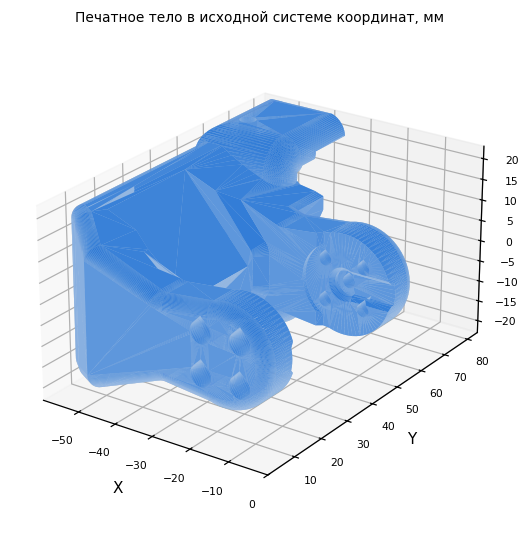

In [10]:
def select_printable(mesh):
    parts = mesh.split(only_watertight=False)
    closed = [p for p in parts if p.is_watertight and p.is_winding_consistent and p.volume > 0]
    assert closed, "Нет замкнутого тела с согласованными нормалями и V > 0"
    main = max(closed, key=lambda p: p.volume)
    lo, hi = main.bounds
    cavities = [p for p in parts if p.is_watertight and p.volume < 0
                and np.all(p.bounds[0] >= lo) and np.all(p.bounds[1] <= hi)]
    body = trimesh.util.concatenate([main] + cavities) if cavities else main.copy()
    rest = [p for p in parts if p is not main and not any(p is c for c in cavities)]
    return body, rest

body, rest = select_printable(raw)
err = float((raw.volume - body.volume) / body.volume * 100)
if abs(err) < 1e-9:
    err = 0.0  # округлительная погрешность конкатенации/копирования сетки
print(f"Печатное тело: {len(body.faces)} граней, watertight={body.is_watertight}, "
      f"нормали согласованы={body.is_winding_consistent}, V={body.volume:.3f} мм³")
print(f"Исключено тел: {len(rest)}; ошибка исходного объёма: {err:+.3f} %")
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")
plot_mesh(ax, body, title="Печатное тело в исходной системе координат, мм")
ax.view_init(elev=24, azim=-55)
plt.tight_layout()
plt.savefig("figures/01_printable_body.png", dpi=160, bbox_inches="tight")
plt.show()

In [11]:
# Самопроверка шага 2 (ничего не меняйте — просто запустите)
assert body.is_watertight and body.volume > 0, "Печатное тело должно быть замкнутым и иметь положительный объём (TODO-2.1)"
assert isinstance(err, float), "err должно быть числом: оберните выражение в float(...) (TODO-2.3)"
print("Шаг 2: ок")

Шаг 2: ок


**Что получили и что это значит.** В файле одно замкнутое печатное тело; исключать вспомогательную геометрию или ремонтировать сетку не потребовалось. Отдельных внутренних оболочек с отрицательным объёмом нет; отверстия и открытые выемки составляют часть единой поверхности и не являются отдельными телами. Ошибка «сырого» объёма составляет 0.000 %, поскольку после перевода единиц исходная сетка совпадает с печатным телом.

### Шаг 3. Геометрические характеристики печатного тела

Вычисляем $V$, $A$, габариты, $k=V/(L_xL_yL_z)$, $A/V$ и $2V/A$.
Оценка доли оболочек: $\min(1,A n_w w/V)$; $n_w=2$, $w=1{,}125d$.
Величина $2V/A$ — характерная геометрическая оценка, а не измеренная минимальная толщина стенки.

In [12]:
V, A = body.volume, body.area          # объём, мм³, и площадь, мм², печатного тела
Lx, Ly, Lz = body.extents              # габариты, мм

geom = pd.Series({
    "габариты, мм": f"{Lx:.1f} × {Ly:.1f} × {Lz:.1f}",     # готово
    "объём V, см³": V / 1000,
    "площадь A, см²": A / 100,
    "k = V / V_габ": V / (Lx * Ly * Lz),
    "A / V, мм⁻¹": A / V,
    "характерная толщина 2V/A, мм": 2 * V / A,
    "доля оболочек (2 периметра)": min(1, A * WALLS * cfg["line_w"] / V),
    "эйлерова характеристика χ": body.euler_number,          # готово
})
check_filled("TODO-3, таблица geom", geom.to_dict())
geom.to_frame("печатное тело")

,печатное тело
"габариты, мм",59.8 × 84.2 × 46.0
"объём V, см³",68.803
"площадь A, см²",181.873
k = V / V_габ,0.297
"A / V, мм⁻¹",0.264
"характерная толщина 2V/A, мм",7.566
доля оболочек (2 периметра),0.238
эйлерова характеристика χ,-36


**Что получили и что это значит.** Объём V = 68.803 см³, площадь A = 181.873 см²; коэффициент k = 0.297: материал занимает примерно 29.7 % габаритного параллелепипеда. Отношение A/V = 0.2643 мм⁻¹, характерная толщина 2V/A = 7.566 мм; это не минимальная стенка. Оболочки занимают 23.79 % сплошного объёма и дают 50.99 % расчётного объёма пластика детали при 30 % заполнения: влияние заполнения здесь заметно.

### Шаг 4. Сравнение шести ориентаций

Название обозначает ось исходной модели, направленную вверх вдоль Z принтера.
Сравниваем высоту, число слоёв, площадь контакта, площадь нависаний и геометрическую оценку поддержек.
Грани в пределах 0,2 мм от стола считаются лежащими на столе — это допуск учебной модели контакта.
Для ABS увеличиваем вес контакта: $score=0{,}45\widehat{V}_{sup}+0{,}20\widehat{H}+0{,}35(1-\widehat{A}_{contact})$.
Крышка означает деление на максимум соответствующего показателя среди шести ориентаций.
Это инженерная эвристика для сравнения, а не прогноз коробления или прочности.

In [13]:
ORIENTATIONS = {   # какая ось модели смотрит ВВЕРХ (вдоль Z принтера)
    "+Z": (0, 0, 0), "-Z": (180, 0, 0), "+X": (0, -90, 0), "-X": (0, 90, 0), "+Y": (90, 0, 0), "-Y": (-90, 0, 0),
}

def orient(mesh, key):
    """Поворачивает модель и ставит её на стол (z_min = 0, x_min = y_min = 0)."""
    T = trimesh.transformations.euler_matrix(*np.radians(ORIENTATIONS[key]))
    g = mesh.copy(); g.apply_transform(T); g.apply_translation(-g.bounds[0])
    return g

In [14]:
def orientation_metrics(g, thr=OVERHANG_DEG, bed_tol=0.2):
    n, c, a = g.face_normals, g.triangles_center, g.area_faces   # нормали, центры и площади граней
    on_bed = c[:, 2] < bed_tol                                    # грани, лежащие на столе
    overhang = (n[:, 2] < -math.cos(math.radians(thr))) & ~on_bed
    contact = a[(n[:, 2] < -0.99) & on_bed].sum()
    support = (a[overhang] * -n[overhang, 2] * c[overhang, 2]).sum() / 1000
    check_filled("TODO-4, orientation_metrics", {"overhang": overhang, "contact": contact, "support": support})
    return dict(H_mm=g.extents[2], contact_mm2=contact, overhang_mm2=a[overhang].sum(), support_cm3=support,
                com_height_rel=g.center_mass[2] / g.extents[2],
                fits_bed=bool(np.all(np.sort(g.extents[:2]) <= np.sort(BED_MM[:2])) and g.extents[2] <= BED_MM[2])), overhang


rows, masks, oriented = [], {}, {}
for key in ORIENTATIONS:                       # перебираем 6 ориентаций и считаем показатели для каждой
    g = orient(body, key)
    m, mask = orientation_metrics(g)
    m["layers"] = math.ceil(m["H_mm"] / cfg["layer_mm"])
    rows.append({"orientation": key, **m}); masks[key] = mask; oriented[key] = g
ori = pd.DataFrame(rows).set_index("orientation")

# Интегральная оценка: меньше поддержек и высоты, больше контакт — лучше. Веса можно изменить с обоснованием.
norm = lambda s: s / s.max() if s.max() > 0 else s * 0
ori["score"] = 0.45 * norm(ori.support_cm3) + 0.20 * norm(ori.H_mm) + 0.35 * (1 - norm(ori.contact_mm2))
ori = ori.sort_values("score")
best = ori.loc[ori.fits_bed].index[0]      # лучшая по score; можно заменить своим выбором с обоснованием, например best = "+Y"
assert len(ori) == 6 and ori.loc[best, "fits_bed"]
assert np.isclose(oriented[best].bounds[0, 2], 0)
# Контроль определения «ось вверх», включая знак оси.
for key, angles in ORIENTATIONS.items():
    axis = np.eye(3)["XYZ".index(key[1])] * (1 if key[0] == "+" else -1)
    R = trimesh.transformations.euler_matrix(*np.radians(angles))[:3, :3]
    assert np.allclose(R @ axis, [0, 0, 1])
print("Шаг 4: ок; выбрана ориентация", best)
ori

Шаг 4: ок; выбрана ориентация +X


,H_mm,contact_mm2,overhang_mm2,support_cm3,com_height_rel,fits_bed,layers,score
orientation,,,,,,,,
+X,59.8,2366.761,881.217,21.035,0.276,True,374,0.234
+Z,46.0,280.099,2112.567,26.071,0.496,True,288,0.532
-Z,46.0,274.495,2436.597,34.436,0.504,True,288,0.569
+Y,84.2,742.668,2034.799,62.784,0.460,True,527,0.714
-X,59.8,40.993,3356.296,103.212,0.724,True,374,0.936
-Y,84.2,162.895,2883.783,97.874,0.540,True,527,0.953


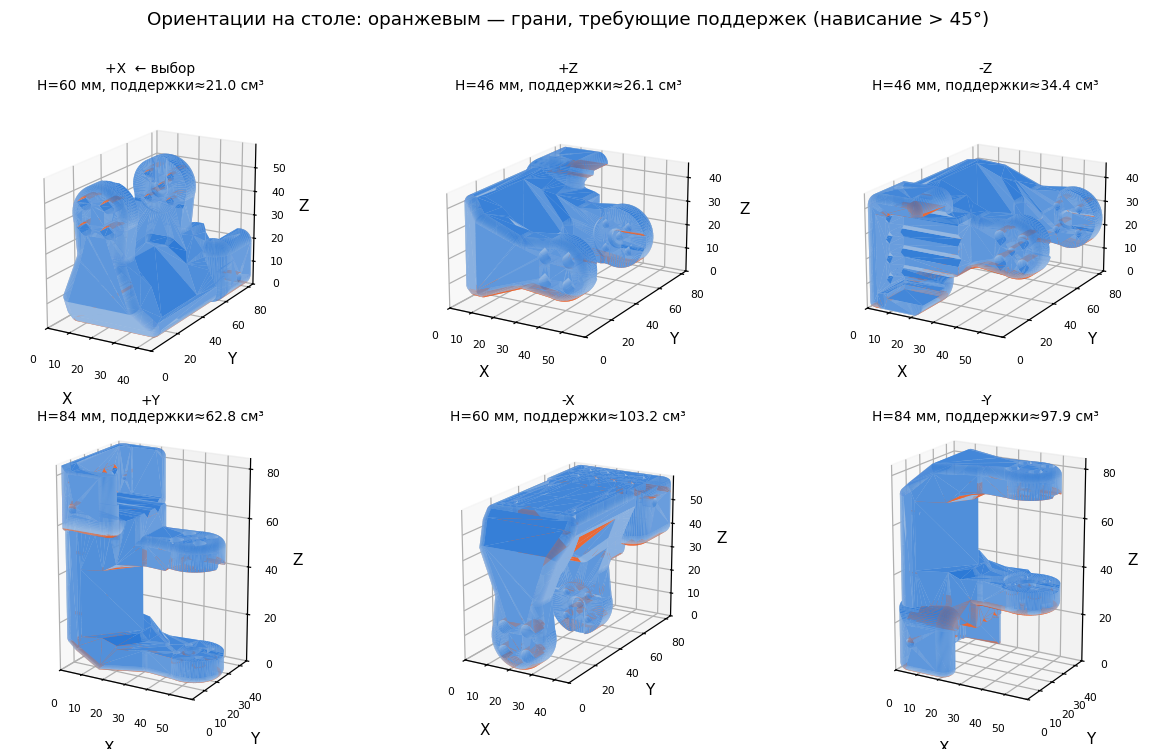

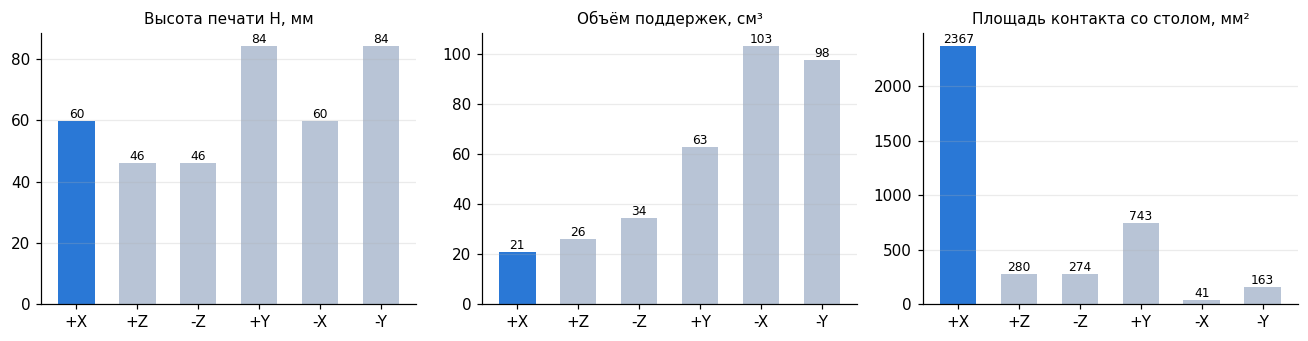

In [15]:
fig = plt.figure(figsize=(12, 6.5))
for i, key in enumerate(ori.index):
    ax = fig.add_subplot(2, 3, i + 1, projection="3d")
    r = ori.loc[key]
    plot_mesh(ax, oriented[key], highlight=masks[key],
              title=f"{key}{'  ← выбор' if key == best else ''}\nH={r.H_mm:.0f} мм, поддержки≈{r.support_cm3:.1f} см³")
    ax.view_init(elev=18, azim=-60)
plt.suptitle("Ориентации на столе: оранжевым — грани, требующие поддержек (нависание > 45°)", y=1.0)
plt.tight_layout(); plt.savefig("figures/02_orientations.png", dpi=160, bbox_inches="tight"); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, ttl in zip(axs, ["H_mm", "support_cm3", "contact_mm2"],
                        ["Высота печати H, мм", "Объём поддержек, см³", "Площадь контакта со столом, мм²"]):
    colors = [C_MODEL if k == best else "#b8c4d6" for k in ori.index]
    ax.bar(ori.index, ori[col], color=colors, width=0.6)
    ax.set_title(ttl, fontsize=10); ax.grid(axis="x", visible=False)
    for x, y in zip(ori.index, ori[col]):
        ax.text(x, y, f"{y:.0f}" if y >= 10 else f"{y:.1f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig("figures/03_orientation_metrics.png", dpi=160, bbox_inches="tight"); plt.show()

**Что получили и что это значит.** Выбрана **+X**: H = 59.80 мм, 374 слоя, контакт 2366.76 мм², площадь нависаний 881.22 мм², оценка поддержек 21.035 см³. Самая низкая ориентация +Z одновременно соответствует положению «как в файле»: H = 46.00 мм, 288 слоёв, контакт 280.10 мм², поддержки 26.071 см³; у +X контакт больше в 8.45 раза, а поддержек меньше на 19.3 %, хотя слоёв больше. Для ABS большая площадь опоры полезна против отрыва и коробления, поэтому ей присвоен вес 0,35 в score; вариант −X особенно невыгоден: контакт 40.99 мм² и поддержки 103.212 см³. При +X исходные направления Y и Z лежат в плоскости слоёв: протяжённая часть вдоль Y не печатается вертикальной колонной; это разумно для передачи изгиба вдоль узла, но нагрузки поперёк слоёв по исходной X сохраняют риск расслоения, а количественная прочность без схемы сил и испытаний не установлена.

### Шаг 5. Высота слоя, число слоёв и время печати

$N=\lceil H/h\rceil$, $Q=1{,}125d h v$, $t=(V_{extr}+0{,}15V_{sup})/(3600Q)$.
Сравниваем шесть высот слоя, включая заданные 0,16 мм; для сопла 0,4 мм проверяем $h\le0{,}30$ мм.
Модель оболочки: $V_{shell}=\min(V,A n_w w)$, $V_{extr}=V_{shell}+\varphi(V-V_{shell})$.

,layers,Q_mm3_s,time_h,ok_for_nozzle
layer_mm,,,,
0.08,748,1.62,6.045,True
0.12,499,2.43,4.030,True
0.16,374,3.24,3.022,True
0.20,299,4.05,2.418,True
0.24,250,4.86,2.015,True
0.28,214,5.67,1.727,True


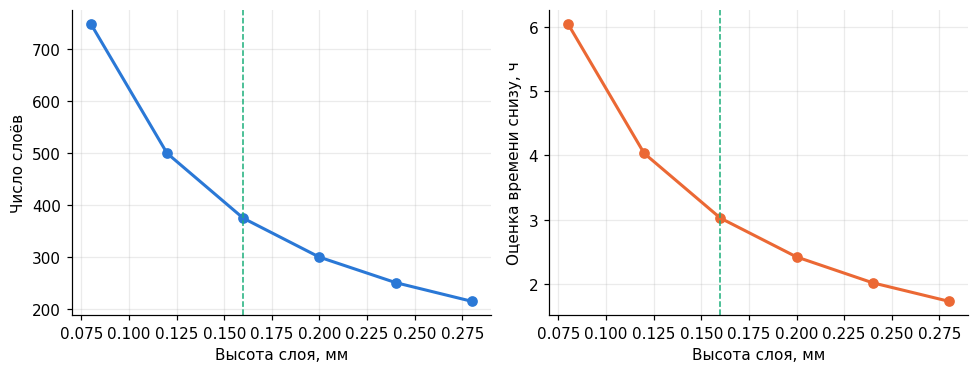

In [16]:
def extruded_volume(V, A, infill, line_w, walls=WALLS):
    """Объём, который выдавит принтер: оболочки + заполнение (мм³). Возвращает (V_extr, V_shell)."""
    shell = min(V, A * walls * line_w)
    v_extr = shell + infill * (V - shell)
    check_filled("TODO-5.1–5.2, extruded_volume", {"shell": shell, "v_extr": v_extr})
    return v_extr, shell


def print_time_h(v_extr_mm3, layer, nozzle, speed):
    """Оценка времени печати снизу, ч, и производительность Q, мм³/с."""
    Q = 1.125 * nozzle * layer * speed
    check_filled("TODO-5.3, print_time_h", {"Q": Q})
    return v_extr_mm3 / Q / 3600, Q


# Готовый расчёт: время и число слоёв для шести значений высоты слоя
H = ori.loc[best, "H_mm"]
sup = ori.loc[best, "support_cm3"] * 1000
rows = []
for h in [0.08, 0.12, 0.16, 0.20, 0.24, 0.28]:
    v_ext, _ = extruded_volume(V, A, cfg["infill_pct"] / 100, cfg["line_w"])
    t, Q = print_time_h(v_ext + SUPPORT_DENSITY * sup, h, cfg["nozzle_mm"], cfg["speed"])
    rows.append(dict(layer_mm=h, layers=math.ceil(H / h), Q_mm3_s=Q, time_h=t, ok_for_nozzle=h <= 0.75 * cfg["nozzle_mm"]))
layers_df = pd.DataFrame(rows).set_index("layer_mm")
layers_df

display(layers_df)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
axs[0].plot(layers_df.index, layers_df.layers, marker="o", color=C_MODEL)
axs[0].set(xlabel="Высота слоя, мм", ylabel="Число слоёв")
axs[1].plot(layers_df.index, layers_df.time_h, marker="o", color=C_WARN)
axs[1].set(xlabel="Высота слоя, мм", ylabel="Оценка времени снизу, ч")
for ax in axs:
    ax.axvline(cfg["layer_mm"], ls="--", color=C_OK, lw=1)
plt.tight_layout(); plt.savefig("figures/04_layers_and_time.png", dpi=160); plt.show()

In [17]:
# Самопроверка шага 5 (ничего не меняйте — просто запустите)
r = layers_df.time_h
assert 1.8 < r.loc[0.12] / r.loc[0.24] < 2.2, ("Время должно быть обратно пропорционально h: "
                                               "проверьте, что в Q (TODO-5.3) входит layer")
print("Шаг 5: ок")

Шаг 5: ок


**Что получили и что это значит.** При h = 0,16 мм получены 374 слоя, Q = 3.240 мм³/с и t ≈ 3.022 ч. При 0,12 мм — 499 слоёв и 4.030 ч, при 0,20 мм — 299 слоёв и 2.418 ч; тонкий слой улучшает разрешение по высоте ценой времени. В данной модели переход 0,24 → 0,12 мм увеличивает время точно в 2.0 раза при неизменных w, v и объёме экструзии. Это оценка снизу при непрерывной подаче: не учтены холостые перемещения, ускорения, нагрев, охлаждение и brim; дополнительно приближен сам расход пластика, поэтому строгой гарантированной нижней границей реальной печати число не является.

### Шаг 6. Масса, материал и заполнение

$m_{дет}=\rho V_{extr}/1000$, $m_{sup}=\rho\varphi_s V_{sup}/1000$ (объёмы в мм³, плотность в г/см³).
Сравниваем четыре материала при одинаковой геометрии, ориентации и заполнении.
Температуры и скорости взяты из методички; это учебные ориентиры, а не проверенный профиль конкретной катушки.

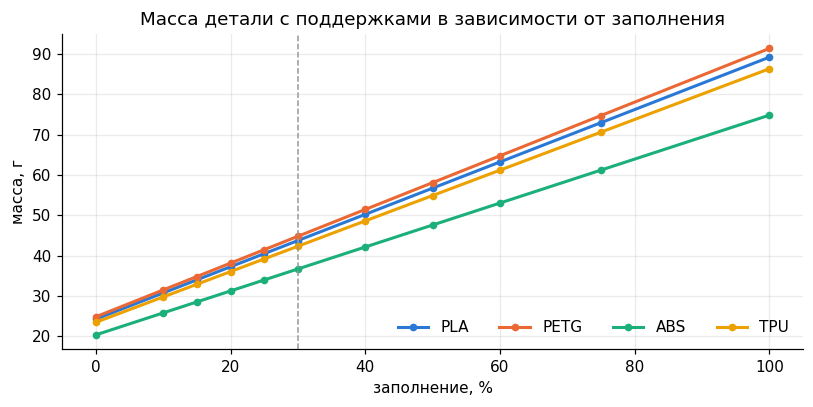

Масса: деталь 33.4 г + поддержки 3.3 г; сплошная 71.6 г


,density_g_cm3,t_nozzle,t_bed,speed_mm_s,heat_C,mass_part_g,mass_support_g,mass_total_g,time_h
PLA,1.24,190–220,50–60,50,55.0,39.803,3.912,43.715,2.720
PETG,1.27,220–250,70–85,40,70.0,40.766,4.007,44.773,3.400
ABS,1.04,230–260,90–110,45,95.0,33.383,3.281,36.664,3.022
TPU,1.20,210–235,30–60,20,NaN,38.519,3.786,42.305,6.801


Шаг 6: ок


In [18]:
infills = np.array([0, 10, 15, 20, 25, 30, 40, 50, 60, 75, 100])
rows = []
for mat, r in MATERIALS.iterrows():          # перебираем материалы…
    for f in infills:                        # …и значения заполнения
        v_e, _ = extruded_volume(V, A, f / 100, cfg["line_w"])
        mass = r.density_g_cm3 * (v_e + SUPPORT_DENSITY * sup) / 1000
        check_filled("TODO-6.1", {"mass": mass})
        rows.append(dict(material=mat, infill=f, mass_g=mass))
mass_df = pd.DataFrame(rows)

v_ext, shell = extruded_volume(V, A, cfg["infill_pct"] / 100, cfg["line_w"])
m_part = cfg["density"] * v_ext / 1000
m_sup = cfg["density"] * SUPPORT_DENSITY * sup / 1000
m_solid = cfg["density"] * V / 1000
check_filled("TODO-6.2–6.4", {"m_part": m_part, "m_sup": m_sup, "m_solid": m_solid})

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for mat, d in mass_df.groupby("material", sort=False):
    ax.plot(d.infill, d.mass_g, color=MAT_COLORS[mat], label=mat, marker="o", ms=4)
ax.axvline(cfg["infill_pct"], color="#999", lw=1, ls="--")
ax.set(title="Масса детали с поддержками в зависимости от заполнения", xlabel="заполнение, %", ylabel="масса, г")
ax.legend(frameon=False, ncol=4); plt.tight_layout(); plt.savefig("figures/05_mass_infill.png", dpi=160); plt.show()
print(f"Масса: деталь {m_part:.1f} г + поддержки {m_sup:.1f} г; сплошная {m_solid:.1f} г")

comparison = MATERIALS.copy()
comparison["mass_part_g"] = comparison.density_g_cm3 * v_ext / 1000
comparison["mass_support_g"] = comparison.density_g_cm3 * SUPPORT_DENSITY * sup / 1000
comparison["mass_total_g"] = comparison.mass_part_g + comparison.mass_support_g
comparison["time_h"] = [print_time_h(v_ext + SUPPORT_DENSITY * sup, cfg["layer_mm"], cfg["nozzle_mm"], v)[0] for v in comparison.speed_mm_s]
display(comparison)
assert 0 <= shell <= v_ext <= V
assert np.isclose(extruded_volume(V, A, 1, cfg["line_w"])[0], V)
print("Шаг 6: ок")

**Что получили и что это значит.** Для ABS масса детали равна 33.383 г, поддержек — 3.281 г, всего — 36.664 г; сплошная деталь без поддержек весила бы 71.555 г. При удвоении заполнения с 30 до 60 % масса самой детали увеличивается до 49.742 г (+49.0 %), так что экономить материал одним изменением заполнения здесь возможно. При тех же 30 % и одинаковой геометрии PLA/PETG/ABS/TPU дают соответственно 43.715/44.773/36.664/42.305 г с поддержками; различие связано с плотностью. ABS по свойствам из методички подходит для жёсткого узла рядом с приводом (теплостойкость около 95 °C), но требует закрытой камеры и контроля усадки; PETG — возможная альтернатива при отсутствии камеры, PLA ограничен нагревом, а TPU слишком гибок для несущего узла целиком.

### Шаг 7. Масштаб: масса, высота и сопряжения

Исследуем диапазон 0,90–1,14 и заданный масштаб 1,04: $L\propto s$, $A\propto s^2$, $V\propto s^3$;
толщину оболочки сохраняем постоянной. Масса в этой таблице относится к самой детали, без поддержек.

Для этой детали методичка использует $D=\max(L_x,L_y,L_z)$ как контрольный размер.
Он не является измеренным посадочным отверстием или межосевым расстоянием.
Поэтому $\Delta=D(s-1)$ здесь показывает изменение общего габарита; все реальные сопряжения также изменятся на 4 %,
но их индивидуальные допуски требуют чертежа. Условные ±0,2 мм — учебный ориентир, а не назначенный конструктором допуск.

Изменение контрольного размера не превышает ±0,2 мм при s ∈ [0.9976; 1.0024] (наибольший габарит звена (межосевые расстояния в URDF), D = 84.2 мм)
При вашем s = 1.04: Δ = +3.37 мм (допуск ±0.2 мм)


,H_mm,V_cm3,mass_g,delta_fit_mm
scale,,,,
0.90,53.820,50.157,25.301,-8.420
0.95,56.810,58.990,29.159,-4.210
1.00,59.800,68.803,33.383,0.000
1.04,62.192,77.394,37.036,3.368
1.05,62.790,79.648,37.988,4.210
1.10,65.780,91.577,42.991,8.420


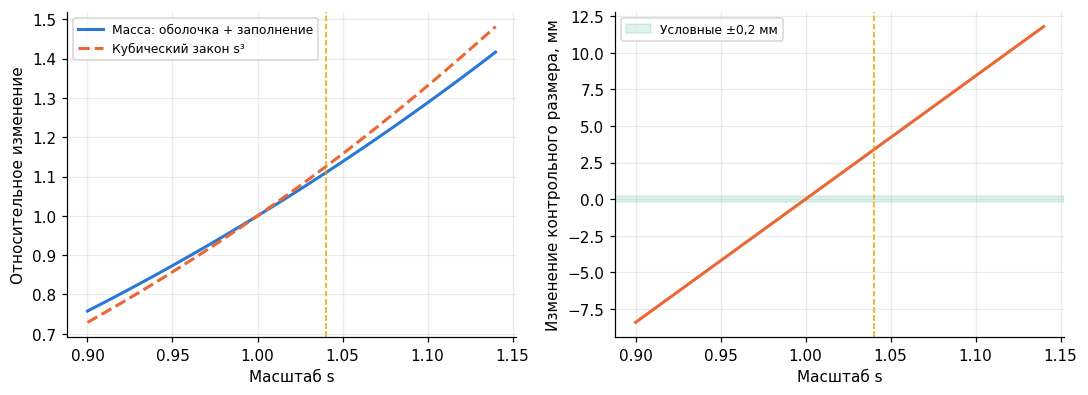

Шаг 7: ок


In [19]:
scales = np.round(np.arange(0.90, 1.141, 0.01), 2)      # масштабы 0.90, 0.91, …, 1.14
fit_name = FIT_DIMS[cfg["fit"]]
D = FIT_SIZE.get(cfg["fit"], body.extents.max())       # посадочный размер, мм
TOL = 0.2                                               # точность FDM-принтера, мм
rows = []
for s in scales:
    v_ext_s, _ = extruded_volume(V * s**3, A * s**2, cfg["infill_pct"] / 100, cfg["line_w"])
    H_s = H * s
    V_s = V * s**3 / 1000
    m_s = cfg["density"] * v_ext_s / 1000
    delta = D * (s - 1)
    check_filled("TODO-7", {"H_s": H_s, "V_s": V_s, "m_s": m_s, "delta": delta})
    rows.append(dict(scale=s, H_mm=H_s, V_cm3=V_s, mass_g=m_s, delta_fit_mm=delta))
scale_df = pd.DataFrame(rows).set_index("scale")
print(f"Изменение контрольного размера не превышает ±0,2 мм при s ∈ [{1 - TOL / D:.4f}; {1 + TOL / D:.4f}] ({fit_name}, D = {D:.1f} мм)")
print(f"При вашем s = {cfg['scale']}: Δ = {D * (cfg['scale'] - 1):+.2f} мм (допуск ±{TOL} мм)")
display(scale_df.loc[[0.90, 0.95, 1.00, cfg["scale"], 1.05, 1.10]])
fig, axs = plt.subplots(1, 2, figsize=(10, 3.7))
axs[0].plot(scale_df.index, scale_df.mass_g / m_part, label="Масса: оболочка + заполнение", color=C_MODEL)
axs[0].plot(scales, scales**3, "--", label="Кубический закон s³", color=C_WARN)
axs[0].set(xlabel="Масштаб s", ylabel="Относительное изменение")
axs[0].legend(fontsize=8)
axs[1].plot(scale_df.index, scale_df.delta_fit_mm, color=C_WARN)
axs[1].axhspan(-TOL, TOL, alpha=0.15, color=C_OK, label="Условные ±0,2 мм")
axs[1].set(xlabel="Масштаб s", ylabel="Изменение контрольного размера, мм")
axs[1].legend(fontsize=8)
for ax in axs:
    ax.axvline(cfg["scale"], color=C_ALT, ls="--", lw=1)
plt.tight_layout(); plt.savefig("figures/06_scale.png", dpi=160); plt.show()
assert np.isclose(scale_df.loc[1.0, "mass_g"], m_part)
print("Шаг 7: ок")

**Что получили и что это значит.** При s = 1,04 контрольный габарит D = 84.20 мм увеличивается на Δ = +3.368 мм, существенно больше условных ±0,2 мм; номинальные 24,8 мм, если они есть в сопряжении, также изменились бы на +0,992 мм. Объём становится 77.394 см³ (+12,49 %), масса детали — 37.036 г (+10.94 %): при ненасыщенной оболочке она растёт медленнее s³ из-за постоянной толщины стенки. Печатать функциональный узел следует в масштабе **1,00**; масштабирование изменяет отверстия, посадки и размеры связанного звена. Для согласованной модели URDF пришлось бы пересчитать геометрию, позиции суставов и инерционные параметры; изменение одного STL этого не делает.

### Шаг 8. Виртуальный слайс и независимая проверка объёма

Строим сечения в серединах слоёв выбранной ориентации. Объём приближаем суммой $V_{срезов}=\sum_i S_i\Delta z_i$;
толщина последнего слоя может быть меньше номинальных 0,16 мм.
Площади `Path2D.area` учитывают отверстия. Кроме профиля площадей и числа островов, показываем контуры нескольких сечений.

Увеличение числа островов само по себе не доказывает появление участка «в воздухе»: существующий контур может разделиться.
Для диагностики новых неподдержанных областей дополнительно сравниваем соседние сечения в общей плоскости XY.

Слоёв: 374; Σ(S·Δz)=68796.138 мм³; mesh.volume=68803.052 мм³
Расхождение: 0.0100 %; последний слой: 0.1200 мм


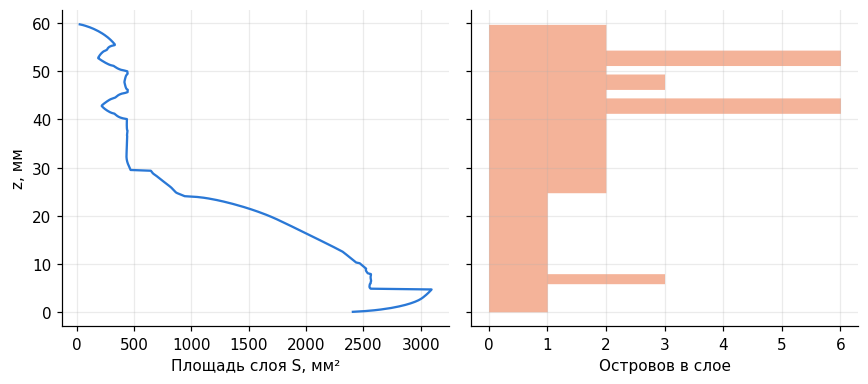

,z_mm,"новая площадь, мм²"
0,0.24,77.000
1,0.40,40.863
2,0.56,23.416
3,0.72,13.844
4,0.88,6.756
5,1.04,2.755
6,1.20,1.920
7,1.36,0.715


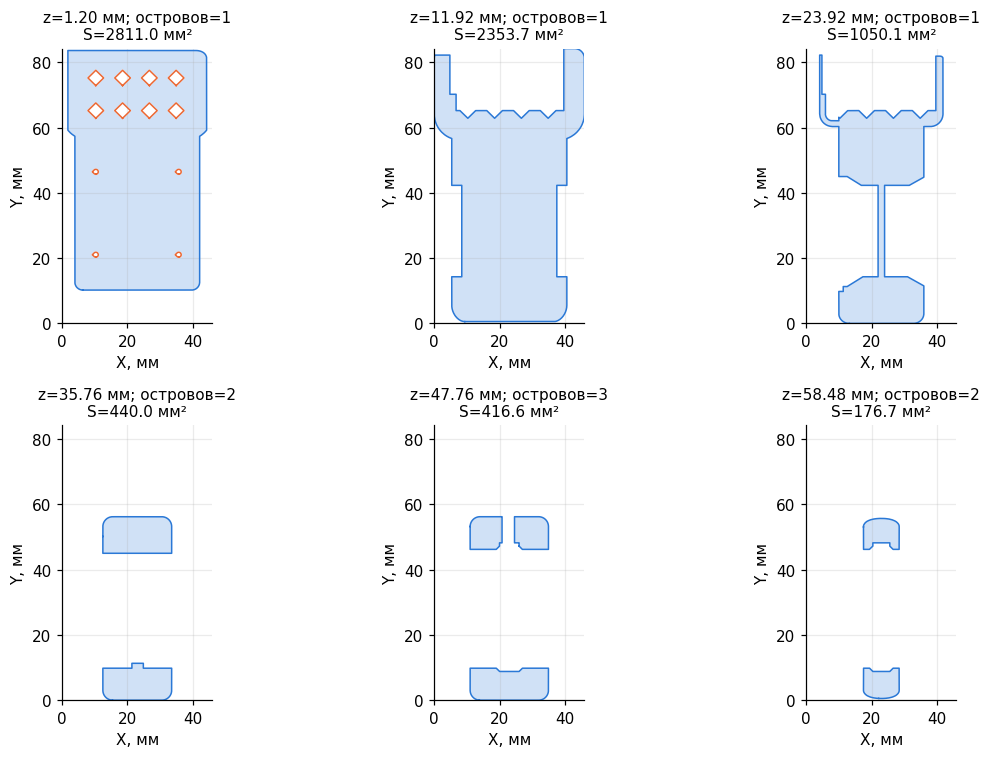

In [20]:
g = oriented[best]
h = cfg["layer_mm"]
edges = np.r_[np.arange(0.0, g.extents[2], h), g.extents[2]]
thicknesses = np.diff(edges)
zs = (edges[:-1] + edges[1:]) / 2
sections = g.section_multiplane(plane_origin=[0, 0, 0], plane_normal=[0, 0, 1], heights=zs)
layer_area = np.array([s.area if s is not None else 0.0 for s in sections])
islands = np.array([len(s.polygons_full) if s is not None else 0 for s in sections])
V_slices = float(np.dot(layer_area, thicknesses))
slice_error_pct = abs(V_slices / g.volume - 1) * 100
print(f"Слоёв: {len(zs)}; Σ(S·Δz)={V_slices:.3f} мм³; mesh.volume={g.volume:.3f} мм³")
print(f"Расхождение: {slice_error_pct:.4f} %; последний слой: {thicknesses[-1]:.4f} мм")
assert len(zs) == math.ceil(g.extents[2] / h)

fig, axs = plt.subplots(1, 2, figsize=(8, 3.6), sharey=True)
axs[0].plot(layer_area, zs, color=C_MODEL, lw=1.5)
axs[0].set(xlabel="Площадь слоя S, мм²", ylabel="z, мм")
axs[1].fill_betweenx(zs, 0, islands, step="mid", color=C_WARN, alpha=0.5, lw=0)
axs[1].set(xlabel="Островов в слое")
plt.tight_layout(); plt.savefig("figures/07_layer_profile.png", dpi=160); plt.show()

# Контуры в координатах XY принтера: преобразуем из локальной плоскости сечения.
from shapely.geometry import Polygon
from shapely.ops import unary_union

def to_xy_polygon(polygon, transform):
    def ring_xy(ring):
        points = np.asarray(ring.coords)
        xyz = trimesh.transform_points(np.c_[points, np.zeros(len(points))], transform)
        return xyz[:, :2]
    return Polygon(ring_xy(polygon.exterior), [ring_xy(r) for r in polygon.interiors])

xy_sections = []
for section in sections:
    if section is None:
        xy_sections.append(Polygon())
    else:
        xy_sections.append(unary_union([to_xy_polygon(p, section.metadata["to_3D"]) for p in section.polygons_full]))

# Учебный индикатор: новая площадь за пределами контура предыдущего слоя,
# расширенного на Δz*tan(45°). Не учитывает мосты, траектории и реальные поддержки.
unsupported_area = np.zeros(len(zs))
for i in range(1, len(zs)):
    reach = (zs[i] - zs[i-1]) * math.tan(math.radians(OVERHANG_DEG))
    unsupported_area[i] = xy_sections[i].difference(xy_sections[i-1].buffer(reach)).area
unsupported_indices = np.flatnonzero(unsupported_area > 0.5)  # отсечка малых численных/геометрических участков
display(pd.DataFrame({"z_mm": zs[unsupported_indices], "новая площадь, мм²": unsupported_area[unsupported_indices]}).head(8))

indices = np.unique(np.clip((np.array([0.02, 0.20, 0.40, 0.60, 0.80, 0.98]) * (len(zs)-1)).astype(int), 0, len(zs)-1))
fig, axs = plt.subplots(2, 3, figsize=(11, 7))
for ax, i in zip(axs.flat, indices):
    shape = xy_sections[i]
    polygons = [shape] if isinstance(shape, Polygon) else list(shape.geoms)
    for polygon in polygons:
        x, y = polygon.exterior.xy
        ax.fill(x, y, facecolor=C_MODEL, alpha=0.22)
        ax.plot(x, y, color=C_MODEL, lw=1)
        for ring in polygon.interiors:
            ax.fill(*ring.xy, color="white")
            ax.plot(*ring.xy, color=C_WARN, lw=1)
    ax.set_title(f"z={zs[i]:.2f} мм; островов={islands[i]}\nS={layer_area[i]:.1f} мм²", fontsize=10)
    ax.set(xlabel="X, мм", ylabel="Y, мм")
    ax.set_aspect("equal")
    ax.set_xlim(0, g.extents[0]); ax.set_ylim(0, g.extents[1])
plt.tight_layout(); plt.savefig("figures/08_sections.png", dpi=160); plt.show()

In [21]:
# Самопроверка шага 8 (ничего не меняйте — просто запустите)
assert abs(V_slices / g.volume - 1) < 0.01, ("Объём по слоям должен совпадать с объёмом сетки с точностью до 1 %: "
                                             "проверьте, что сумма площадей умножена на h (TODO-8)")
print("Шаг 8: ок")

Шаг 8: ок


**Что получили и что это значит.** Сумма по 374 слоям даёт V_срезов = 68796.138 мм³ против 68803.052 мм³ по сетке, расхождение 0.0100 % < 1 %. Минимальное ненулевое сечение имеет площадь 27.22 мм² на высоте 59.74 мм; максимальное число островов равно 6. Первый прирост неподдержанной площади свыше 0,5 мм² обнаружен при z=0.24 мм (77.00 мм²); наибольший — 77.00 мм² при z=0.24 мм. Эти участки требуют проверки поддержек в слайсере и согласуются с ненулевой площадью нависающих граней 881.22 мм², но сопоставление является качественным: контурный индикатор не учитывает допустимую длину мостов. Проверка объёма подтверждает согласованность двух расчётов, а не отсутствие всех возможных дефектов STL.

### Шаг 9. Итоговая карта параметров печати

Сохраняем материал и режим варианта. Для снижения коробления ABS выбираем закрытую камеру,
brim 5 мм и ориентацию с большой площадью контакта. Brim и дополнительные служебные траектории в расчёт массы и времени не включены.
Температуры 245/100 °C — начальные уставки внутри диапазонов методички; их уточняют по катушке и принтеру.
Масштаб печати — 1:1.

In [22]:
t_h, Q = print_time_h(v_ext + SUPPORT_DENSITY * sup, cfg["layer_mm"], cfg["nozzle_mm"], cfg["speed"])
mat = MATERIALS.loc[cfg["material"]]
r = ori.loc[best]
print_map = pd.Series({
    "студент": STUDENT,
    "группа": GROUP,
    "вариант": VARIANT,
    "деталь": cfg["part"],
    "масштаб": 1.0,
    "ориентация (ось вверх)": best,
    "габарит на столе, мм": " × ".join(f"{v:.2f}" for v in oriented[best].extents),
    "материал": cfg["material"],
    "T сопла / стола, °C": "245 / 100 (исходные уставки)",
    "диапазоны по методичке, °C": f"{mat.t_nozzle} / {mat.t_bed}",
    "сопло / ширина линии, мм": f"{cfg['nozzle_mm']:.2f} / {cfg['line_w']:.2f}",
    "скорость печати, мм/с": cfg["speed"],
    "высота слоя, мм": cfg["layer_mm"],
    "число слоёв": math.ceil(r.H_mm / cfg["layer_mm"]),
    "периметры": WALLS,
    "заполнение, %": cfg["infill_pct"],
    "поддержки": f"да; геометрическая оценка {r.support_cm3:.3f} см³; заполнение 15 %; тип и размещение уточнить в слайсере",
    "адгезия": "brim 5 мм; чистый стол; совместимое с ABS покрытие",
    "камера / вентиляция": "закрытая камера, вытяжка; исключить сквозняки",
    "масса детали, г": round(m_part, 3),
    "масса поддержек, г": round(m_sup, 3),
    "масса детали + поддержек, г": round(m_part + m_sup, 3),
    "оценка времени (снизу), ч": round(t_h, 3),
    "производительность Q, мм³/с": round(Q, 3),
    "ограничения": "Без brim, purge, перемещений, ускорений, нагрева и охлаждения; прочность не проверена испытаниями",
})
check_filled("шаг 9, карта параметров", print_map.to_dict())
out = Path(f"print_map_variant_{VARIANT:02d}.csv")
print_map.to_csv(out, header=["значение"], encoding="utf-8-sig")
print_map.to_frame("карта параметров печати")

,карта параметров печати
студент,Юшкова Ольга Марьяновна
группа,ИНДОР-221
вариант,17
деталь,rotation_pitch_so101_v1
масштаб,1.0
ориентация (ось вверх),+X
"габарит на столе, мм",46.00 × 84.20 × 59.80
материал,ABS
"T сопла / стола, °C",245 / 100 (исходные уставки)
"диапазоны по методичке, °C",230–260 / 90–110


In [23]:
# Самопроверка шага 9 (ничего не меняйте — просто запустите)
assert not any(v is ... for v in print_map.values), "Заполните все поля карты (TODO-9)"
assert out.exists(), "Файл карты не сохранён: перезапустите ячейку выше"
print("Шаг 9: ок — файл", out, "(скачайте его: панель Files слева → файл → Download)")

Шаг 9: ок — файл print_map_variant_17.csv (скачайте его: панель Files слева → файл → Download)


### Шаг 10. Аналитический вывод

1. **Модель.** STL узла поворота `rotation_pitch_so101_v1` переведён из метров в миллиметры. Получена одна замкнутая оболочка с согласованными нормалями; ремонт и исключение геометрии не потребовались. Габариты — 59,80 × 84,20 × 46,00 мм, объём — 68.803 см³, площадь — 181.873 см²; ошибка исходного объёма — 0.000 %.
2. **Ориентация.** Рекомендуется +X: высота 59.80 мм, 374 слоя, контакт 2366.76 мм² и поддержки около 21.035 см³. По сравнению с +Z высота увеличивается с 46.00 до 59.80 мм, зато контакт больше в 8.45 раза и оценка поддержек меньше на 19.3 %. Для ABS это обосновывает большую опору и brim 5 мм; исходная Y лежит вдоль слоёв, однако прочность при нагрузке по исходной X отдельно не доказана.
3. **Материал и режим.** ABS, сопло 0,4 мм, линия 0,45 мм, слой 0,16 мм, два периметра, заполнение 30 %, скорость 45 мм/с; стартовые температуры 245/100 °C, закрытая камера и вытяжка. Масса детали — 33.383 г, поддержек — 3.281 г, всего — 36.664 г; время по Q = 3.240 мм³/с составляет 3.022 ч. При 0,12/0,20 мм время изменяется до 4.030/2.418 ч; при 60 % заполнения масса детали — 49.742 г. ABS пригоден условно при соблюдении режима; без камеры разумно отдельно рассмотреть PETG и пересчитать профиль.
4. **Масштаб.** При s = 1,04 габарит 84.20 мм изменяется на +3.368 мм, объём — до 77.394 см³, масса — до 37.036 г. Для сохранения сопряжений выбран масштаб **1:1**; фактические посадки и компенсацию усадки ABS проверяют по чертежу и пробным размерам.
5. **Проверка и ограничения.** Объём по срезам — 68796.138 мм³, расхождение с сеткой — 0.0100 %. Модель оболочки A·n_w·w, оценка поддержек через проекции граней и время при постоянном Q приближённые: не построены траектории, не рассчитаны мосты, ускорения, brim, охлаждение и усадка; испытания прочности и реальная печать не проводились. Перед изготовлением требуются слайсер, проверка сопряжений и профиль конкретного ABS.

### Самоконтроль

1. Незамкнутая поверхность не ограничивает тело, поэтому её знаковый объём не даёт надёжной массы. Согласованность нормалей проверяется отдельно.
2. STL не хранит единицы: малые числа сопоставляются с происхождением модели и реальными размерами узла. Здесь масштаб ×1000 подтверждает ожидаемые десятки миллиметров.
3. CAD-ориентация определяется удобством сборки; для печати сравнивают контакт, поддержки, высоту и направление слоёв.
4. При большой доле оболочек заполнение меняет только малый остаток объёма. У исследованного узла остаток достаточно велик, поэтому заполнение заметно влияет на массу.
5. При постоянных w и v уменьшение h с 0,2 до 0,1 мм уменьшает Q вдвое и удваивает расчётное время, если объём экструзии принят неизменным.
6. В ненасыщенной модели оболочка растёт как s², заполнение — как s³. При насыщении оболочки масса может подчиняться s³; универсального строго более медленного роста нет.
7. Масштаб меняет все отверстия и сопряжения, а размеры готовых приводов и крепежа остаются прежними. Допуск нельзя заменить произвольным масштабом всей детали.
8. Протяжённое плечо располагают вдоль плоскости слоёв, чтобы уменьшить риск отрыва слоёв при изгибе; итог зависит от схемы сил и формы узла.

### Источники и воспроизводимость

- Методические указания `lab_03.md` и исходная тетрадка `lab_03_student.ipynb`, предоставленные для работы.
- [Исходная модель, зафиксированная версия курса](https://github.com/BosenkoTM/robotics-course/blob/018dde9d619aad5a5a0c60fd89a4b4cffcfc55b9/01-intro-and-kinematics/assets/urdf/so101/assets/rotation_pitch_so101_v1.stl).
- [Документация trimesh: сетки, объём и сечения](https://trimesh.org/trimesh.base.html), [плоские контуры и площади](https://trimesh.org/trimesh.path.path.html).

Плотности, температурные диапазоны, скорости и расчётные формулы взяты из методички.
Версия STL и контрольная сумма закреплены в коде. Файлы STL не включаются в сдаваемый комплект: при запуске они загружаются автоматически.


In [24]:
# Дополнительная самопроверка единиц, геометрии и согласованности карты.
assert raw.is_watertight and raw.is_winding_consistent and body.volume > 0
assert len(parts) == 1 and len(rest) == 0
assert np.allclose(body.extents, [59.8, 84.2, 46.0], atol=0.001)
assert 0 < V / np.prod(body.extents) < 1
assert best == "+X" and print_map["масштаб"] == 1.0
assert print_map["материал"] == cfg["material"] == "ABS"
assert print_map["число слоёв"] == len(zs)
assert abs(V_slices / V - 1) < 0.01
assert np.isclose(m_part + m_sup, cfg["density"] * (v_ext + SUPPORT_DENSITY * sup) / 1000)
assert not any(value is Ellipsis for value in print_map.values)

nonzero = np.flatnonzero(layer_area > 0)
thin_i = nonzero[np.argmin(layer_area[nonzero])]
if len(unsupported_indices):
    first_i = int(unsupported_indices[0])
    peak_i = int(np.argmax(unsupported_area))
    unsupported_text = (f"Первый прирост неподдержанной площади свыше 0,5 мм² обнаружен при z={zs[first_i]:.2f} мм "
                        f"({unsupported_area[first_i]:.2f} мм²); наибольший — {unsupported_area[peak_i]:.2f} мм² при z={zs[peak_i]:.2f} мм.")
else:
    unsupported_text = "Контурный индикатор не выявил прироста неподдержанной площади свыше 0,5 мм²."

results = {
    "V": float(V), "A": float(A), "k": float(V / np.prod(body.extents)),
    "raw_error": err, "shell_fraction": float(shell/V), "shell_extr_fraction": float(shell/v_ext),
    "H": float(H), "N": int(math.ceil(H/cfg["layer_mm"])), "Q": float(Q), "time": float(t_h),
    "contact": float(ori.loc[best, "contact_mm2"]), "overhang": float(ori.loc[best, "overhang_mm2"]),
    "support_cm3": float(sup/1000), "z_H": float(ori.loc["+Z", "H_mm"]),
    "z_N": int(ori.loc["+Z", "layers"]), "z_contact": float(ori.loc["+Z", "contact_mm2"]),
    "z_support": float(ori.loc["+Z", "support_cm3"]), "minus_x_contact": float(ori.loc["-X", "contact_mm2"]),
    "minus_x_support": float(ori.loc["-X", "support_cm3"]),
    "n012": int(layers_df.loc[0.12, "layers"]), "n020": int(layers_df.loc[0.20, "layers"]),
    "t012": float(layers_df.loc[0.12, "time_h"]), "t020": float(layers_df.loc[0.20, "time_h"]),
    "t024": float(layers_df.loc[0.24, "time_h"]),
    "m_part": float(m_part), "m_sup": float(m_sup), "m_total": float(m_part+m_sup), "m_solid": float(m_solid),
    "m60": float(cfg["density"]*extruded_volume(V,A,0.60,cfg["line_w"])[0]/1000),
    "material_masses": {mat: float(MATERIALS.loc[mat,"density_g_cm3"]*(v_ext+SUPPORT_DENSITY*sup)/1000) for mat in MATERIALS.index},
    "D": float(D), "delta": float(D*(cfg["scale"]-1)),
    "scaled_V": float(V*cfg["scale"]**3), "scaled_m": float(scale_df.loc[cfg["scale"],"mass_g"]),
    "V_slices": float(V_slices), "slice_error": float(slice_error_pct), "slice_count": len(zs),
    "thin_area": float(layer_area[thin_i]), "thin_z": float(zs[thin_i]),
    "max_islands": int(islands.max()), "unsupported_text": unsupported_text,
}
Path("results.json").write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding="utf-8")

readme = f"""# Лабораторная работа № 3. Виртуальный анализ 3D-модели детали SO-101

**Студент:** {STUDENT} · **Группа:** {GROUP} · **Вариант:** {VARIANT}

**Деталь:** {cfg['part']} — узел поворота · **Материал:** ABS · **Слой:** 0,16 мм · **Заполнение:** 30 %

## Основные результаты

| Показатель | Значение |
|---|---|
| Габариты печатного тела, мм | 59,80 × 84,20 × 46,00 |
| Объём V, см³ / площадь A, см² | {V/1000:.3f} / {A/100:.3f} |
| Сетка | Одна замкнутая оболочка; нормали согласованы; 17 672 грани |
| Выбранная ориентация (ось вверх) | {best} |
| Габариты на столе, мм | {' × '.join(f'{v:.2f}' for v in oriented[best].extents)} |
| Площадь контакта со столом, мм² | {ori.loc[best,'contact_mm2']:.2f} |
| Геометрический объём поддержек, см³ | {sup/1000:.3f}; плотность 15 % |
| Число слоёв / время печати (оценка снизу), ч | {len(zs)} / {t_h:.3f} |
| Масса детали / поддержек / всего, г | {m_part:.3f} / {m_sup:.3f} / {m_part+m_sup:.3f} |
| Изменение контрольного габарита при s = 1,04, мм | {D*(cfg['scale']-1):+.3f} |
| Расхождение объёма по слоям, % | {slice_error_pct:.4f} |

## Вывод

Выбрана ориентация {best}: при высоте {H:.2f} мм она даёт контакт {ori.loc[best,'contact_mm2']:.2f} мм² и около {sup/1000:.3f} см³ поддержек; контакт в {ori.loc[best,'contact_mm2']/ori.loc['+Z','contact_mm2']:.2f} раза больше, чем у исходной +Z, что полезно для ABS с риском коробления.
При слое 0,16 мм, двух периметрах и заполнении 30 % расчётная масса детали с поддержками равна {m_part+m_sup:.3f} г, время при постоянной подаче — {t_h:.3f} ч; протяжённое направление исходной Y лежит в плоскости слоёв, но прочность количественно не проверена.
ABS подходит условно при закрытой камере, вытяжке и контроле усадки; стартовые температуры — 245/100 °C, сопло — 0,4 мм, скорость — 45 мм/с, brim — 5 мм.
Масштаб 1,04 увеличивает контрольный габарит 84,20 мм на {D*(cfg['scale']-1):.3f} мм, поэтому для функционального узла рекомендован масштаб 1:1.
Объём по срезам совпадает с объёмом сетки с расхождением {slice_error_pct:.4f} %; оценки массы, поддержек и времени приближённые и не учитывают траектории, brim, нагрев, охлаждение и испытания прочности.

Контрольный габарит не является измеренной посадкой или межосевым расстоянием; фактические сопряжения требуют чертежа и проверки размеров после печати.

## Файлы

- `lab_03_student.ipynb` — решение с таблицами, графиками, пояснениями и самопроверками.
- `print_map_variant_17.csv` — карта параметров печати, UTF-8 с BOM.
- `figures/` — рисунки, также сохранённые в notebook.

## Запуск

1. Открыть [Google Colab](https://colab.research.google.com/) и выбрать **Файл → Открыть блокнот → Загрузить**, указав `lab_03_student.ipynb`.
2. Выполнить **Среда выполнения → Перезапустить сеанс и выполнить все**. GPU не требуется; нужен интернет для библиотек и STL.
3. Убедиться, что все самопроверки завершились сообщением «ок», затем скачать IPYNB с результатами. CSV и README создаются в панели файлов Colab автоматически.

Можно открыть notebook в Jupyter с Python 3.11+ и установленными `ipykernel`, `nbformat`, `nbclient`; необходимые расчётные библиотеки устанавливает первая ячейка.
Результаты уже встроены в файл: для их чтения повторный расчёт не требуется.

## Источники и воспроизводимость

Методические указания `lab_03.md` и шаблон `lab_03_student.ipynb` предоставлены для выполнения работы; формулы, плотности, температуры и скорости приняты из них.
STL загружается из [репозитория курса, фиксированная версия](https://github.com/BosenkoTM/robotics-course/blob/{SOURCE_COMMIT}/01-intro-and-kinematics/assets/urdf/so101/assets/rotation_pitch_so101_v1.stl).
Коммит: `{SOURCE_COMMIT}`. SHA-256 STL: `{EXPECTED_SHA256}`.
Геометрические библиотеки: trimesh 5.1.1, shapely 2.2.0, rtree 1.4.1; фактические версии остальных библиотек выведены в первой ячейке.
Документация: [trimesh — сетки](https://trimesh.org/trimesh.base.html), [плоские контуры](https://trimesh.org/trimesh.path.path.html).

STL-файлы в репозиторий не включаются: тетрадка скачивает проверенную модель автоматически.
"""
Path("README.md").write_text(readme, encoding="utf-8")
print("Все дополнительные проверки: ок")
print("Созданы:", out.name, "README.md и 8 рисунков в figures/")

Все дополнительные проверки: ок
Созданы: print_map_variant_17.csv README.md и 8 рисунков в figures/
